# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [5]:
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [6]:
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [7]:
usage.head() 

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [8]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [9]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [10]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [11]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [12]:

# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())


user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [13]:
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 Nota general: Antes de tratar un nulo necesitaría entender si es faltante (no se capturó) o estructural (no aplica / aún no ocurre). Los estructurales es importante conservarlos e interpretarlos; solo los faltantes se deben imputar o eliminar.

 En users: 
 - la columna City tiene 469 nulos, lo que representa una proporción de 11.7%. Mi recomendación sería investigar e imputar (o dejar como nulo / “Unknown”)	Está en el rango 5-30%; es categórica, así que se imputa con “Unknown” o se deja nula tras revisar si los nulos se concentran en algún plan o reg_date.
 - La columna churn_date tiene 3,534 nulos, lo que representa una proporción de 88.4%. La decisión sería ignorar como columna de fechas, pero conservar como indicadorde si el usuario sigue o no activo. En términos del hint, al superar el 80-90% se eliminaría, pero el nulo significa “usuario activo”, así que se convierte en is_churned en lugar de eliminar la información. Con esto mantengo la única manera de saber qué usuarios siguen o no activos.

En usage:

- La columna duration tiene 22,076 nulos, proporción:55.2%. Mi decisión sería ignorar ya que supera el 30%. No recomiendo imputar porque probablemente solo aplica a ciertos type (nulo estructural).
- La columna length	tiene 17,896 nulos, proporción: 44.7%. Mi decisión sería ignorar / dejar como nulos. Al igual que en duration probablemente aplica solo a otros type, es decir a un tipo de uso particular. Imputarla inventaría datos.
- En el caso de la columna Date tiene 50 nulos, proporción: 0.125%. Mi recomendación es eliminar esas filas. Por que son menos del 5%, así que perderlas casi no afecta el análisis. Por el contrario imputar, la segunda sugerencia del hint, crearía eventos en días en que no ocurrieron y distorsionaría cualquier análisis por tiempo.

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  Se colocó líneas arriba
- Indica qué harías: ¿imputar, eliminar, ignorar?: se indicó líneas arriba por cada DF.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [15]:
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


In [16]:
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- En users: Las columnas user_id no tiene sin sentinelas. Va de 10000 a 13999, es consecutivo y coincide con las 4,000 filas.
Por su  parte, la columna age contiene el sentinela -999 (mínimo de la columna). Una edad no puede ser negativa y menos de 999, así que es un código de “dato desconocido” y no una edad real. Este dato nos distorsiona la media (33.7 contra una mediana de 47) y la desviación estándar (123). Sin él, las edades parecen ir de unos 18 a 79 años. La decisión sería reemplazar -999 por nulo e imputar con la mediana, porque son pocos casos (menos del 5%).
- En usage: Las columnas`id` y `user_id`no tienen sentinels. Las columnas duration y length tienen posibles outliers dado que están muy lejos del 75%

In [18]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print("Valores únicos:", users[col].nunique())
    print(users[col].value_counts(dropna=False))
    print()


Valores únicos: 7
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Valores únicos: 2
Basico     2595
Premium    1405
Name: plan, dtype: int64



- La columna `city` tiene 6 ciudades válidas, 469 nulos y un sentinela de texto “?” que contempla 96 registros. Considerando ambos nos dan 565 faltantes (14.1%). Siguiendo el hint mencionado y estar dentro del rango 5-30% podría reemplazarse “?” por nulo y se imputa todo con “Unknown”. 
- La columna `plan` tiene solo dos categorías (Basico 64.9%, Premium 35.1%), sin nulos ni inconsistencias, y no requiere limpieza.

In [19]:

# explorar columna categórica de usage
usage['type']
print("Valores únicos:", usage['type'].nunique())
print(usage['type'].value_counts(dropna=False))


Valores únicos: 2
text    22092
call    17908
Name: type, dtype: int64


- La columna `type` tiene solo dos categorías: text (55.2%) y call (44.8%), sin nulos ni inconsistencias. No requiere limpieza. 


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
La columna users.age: contiene el sentinela -999, que aparece como valor mínimo de la columna. Una edad no puede ser negativa, así que distorsiona la media (33.7 contra una mediana de 47) y la desviación estándar (123). Era un nulo oculto, pues la columna aparecía con 0 nulos.

La columna users.city: contiene el sentinela de texto “?” en 96 registros (2.4%). Sumado a los 469 nulos, hay 565 datos faltantes (14.1%), más del 11.7% que se veía inicialmente.

Las columnas usage.duration y usage.length: no tienen sentinelas pero sí valores extremos: duration con máximo de 120 (percentil 75 = 6.99) y length con máximo de 1490 (percentil 75 = 64). Se consideran posibles outliers, no nulos ocultos.

Sin valores inválidos: user_id, reg_date y plan en users; id, user_id y type en usage.

  
- ¿Qué acción tomarías?

En la columna users.age reemplazar -999 por nulo e imputar con la mediana que es sólida.
En la columna users.city reemplazar “?” por nulo e imputar con “Unknown”. Evitamos inventar datos
En usage.duration y usage.length no reemplazaría pero sí revisaría los outliers


### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [21]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [22]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [23]:
users['reg_date'].dt.year.value_counts().sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date` hay registros de 2022 (1,314), 2023 (1,316), 2024 (1,330) y 2026 (40). Los datos llegan hasta 2024, por lo que los 40 registros de 2026 (1.0%) son fechas anormales que pueden ser resultado de un error de captura. No hay años negativos ni fechas no convertidas. Se recomienda reemplazan por nulo (NaT) para no inventar fechas y conservar a los usuarios, ya que representan menos del 5%.

In [24]:
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')
usage['date'].dt.year.value_counts(dropna=False).sort_index()


2024.0    39950
NaN          50
Name: date, dtype: int64

`date`en usage contiene únicamente registros de 2024 (39,950, casi el 99.9%) y 50 nulos (0.1%). No hay años futuros, negativos ni anteriores al primer registro de usuarios (2022), por lo que no hay fechas imposibles. La conversión con errors='coerce' no generó nulos adicionales. Los 50 nulos se eliminan por ser menos del 5%.  

Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos). No
- ¿Qué harías con ellas? se detectan 50 nulos que se eliminarían por ser menos del 5%

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [25]:
# Reemplazar -999 por la mediana de age

age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [28]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].isna().sum())
print((users['city'] == '?').sum())

565
0


In [29]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT


# Verificar cambios
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [30]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].apply(lambda x: x.isna().mean())

type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [31]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].apply(lambda x: x.isna().mean())

type
call    0.99933
text    0.00000
Name: length, dtype: float64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`. 
Los nulos de duration (en text) y de length (en call) dependen de type, por lo que se consideran MAR y estructurales. Se dejan como nulos en ambas columnas. Hay unas 28 filas (16 text con duration y 12 call con length) con el dato en la columna que no les corresponde, una inconsistencia menor (<0.1%).

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [32]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = (
    usage.groupby("user_id")
         .agg(cant_mensajes=("is_text", "sum"),
              cant_llamadas=("is_call", "sum"),
              cant_minutos_llamada=("duration", "sum"))
         .reset_index()
)


# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas

# observar resultado
usage_agg.head(3)

In [33]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")

# Usuarios sin registros de uso: 0 mensajes, 0 llamadas, 0 minutos
cols = ["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]
user_profile[cols] = user_profile[cols].fillna(0)

user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [34]:
# Resumen estadístico de las columnas numéricas
cols_num = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]

# Resumen estadístico de las columnas numéricas
user_profile[cols_num].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.136000,5.523000,4.477000,23.311225
std,17.689919,2.359738,2.145139,18.169564
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.107500
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.412500
max,79.000000,17.000000,15.000000,155.690000


In [35]:
# Distribución porcentual del tipo de plan
(user_profile["plan"].value_counts(normalize=True) * 100).round(1)

Basico     64.9
Premium    35.1
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

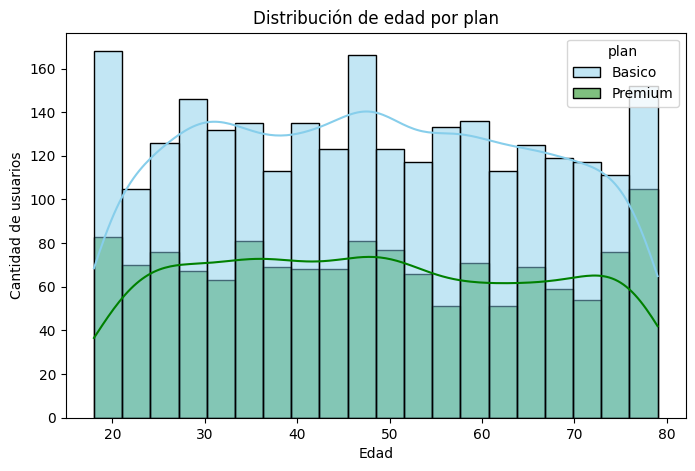

In [36]:
# Histograma para visualizar la edad (age)
%matplotlib inline

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Histograma para visualizar la edad (age)
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='age', hue='plan', bins=20,
             palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de edad por plan')
plt.xlabel('Edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- La edad tiene una distribución aproximadamente uniforme y simétrica, de 18 a 79 años, sin sesgo hacia ninguno de los lados (media 48.1 y mediana 48). Ambos planes siguen la misma forma: no existe un patrón por edad que distinga a los usuarios Premium de los Basico. La mayor altura de Basico se debe a que tiene más usuarios (64.9% contra 35.1%), no a una concentración en alguna franja de edad.

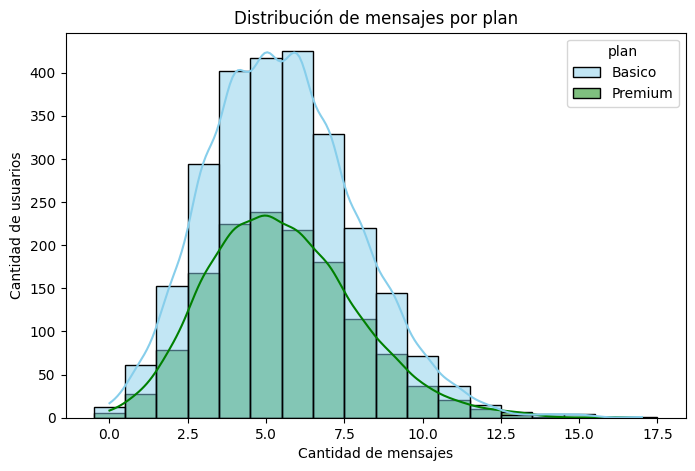

In [37]:
%matplotlib inline

import seaborn as sns
import matplotlib.pyplot as plt

# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', discrete=True,
             palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de mensajes por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- La cantidad de mensajes tiene una distribución sesgada a la derecha: la mayoría de los usuarios envía entre 3 y 8 mensajes, con el pico en 5 (media 5.5, mediana 5), y una cola larga de pocos usuarios que llegan hasta 17.
- No existe un patrón claro por plan: tanto los usuarios Basico como los Premium concentran su pico en torno a 5 mensajes y tienen la misma forma de distribución.
- Los usuarios Basico aparecen en mayor cantidad en todos los valores solo porque son la mayoría (64.9%), no porque envíen más mensajes.
Los usuarios con muy pocos o ningún mensaje, y los que superan los 12, son minoritarios en ambos planes.

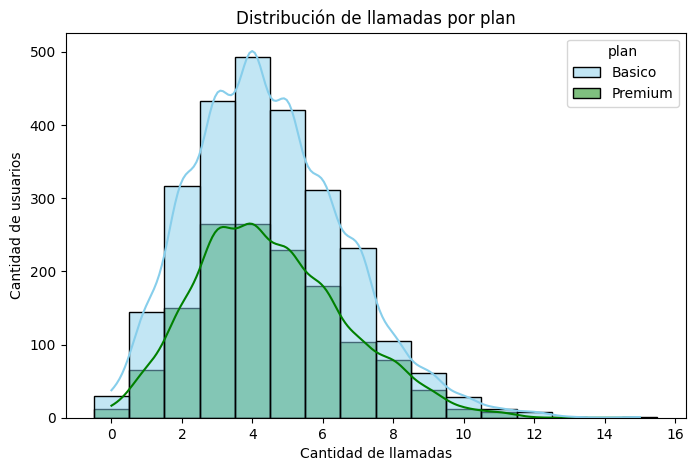

In [38]:
%matplotlib inline

import seaborn as sns
import matplotlib.pyplot as plt

# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', discrete=True,
             palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de llamadas por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- La cantidad de llamadas tiene una distribución sesgada a la derecha: la mayoría de los usuarios hace entre 2 y 7 llamadas, con el pico en 4 (media 4.5, mediana 4), y una cola corta de pocos usuarios que llegan hasta 15.
- No existe un patrón claro por plan: los usuarios Basico y Premium concentran su pico en 4 llamadas y tienen la misma forma de distribución.
- Basico aparece en mayor cantidad en todos los valores solo porque es el plan mayoritario (64.9%), no porque llame más.
- Los usuarios sin llamadas o con más de 10 son minoritarios en ambos planes.

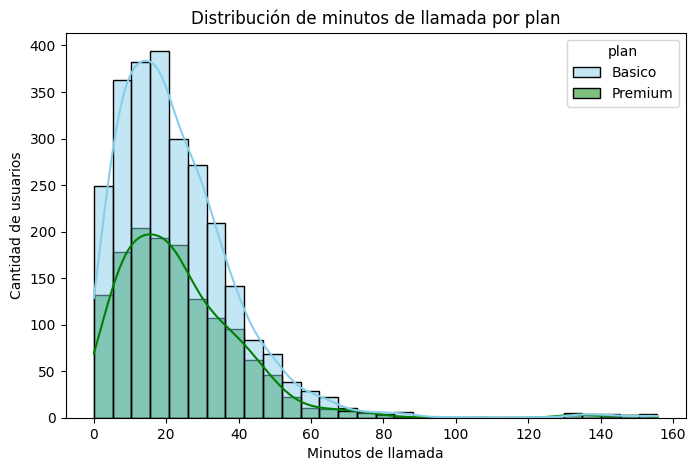

In [39]:
# Histograma para visualizar la cant_minutos_llamada
%matplotlib inline

import seaborn as sns
import matplotlib.pyplot as plt

# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', bins=30,
             palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de minutos de llamada por plan')
plt.xlabel('Minutos de llamada')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- Los minutos de llamada tienen una distribución sesgada a la derecha: la mayoría de los usuarios acumula entre 5 y 35 minutos, con el pico alrededor de 15 minutos (media 23.3, mediana 19.8), y una cola larga de pocos usuarios con valores muy altos.
- No existe un patrón claro por plan: Basico y Premium comparten el mismo pico y la misma forma de distribución; Premium no concentra más minutos que Basico.
- Basico aparece en mayor cantidad en todos los rangos solo porque es el plan mayoritario (64.9%), no porque hable más.
- Se observan posibles valores atípicos entre 130 y 155 minutos, muy alejados del resto (percentil 75 = 31.4), que se analizarán con boxplots.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

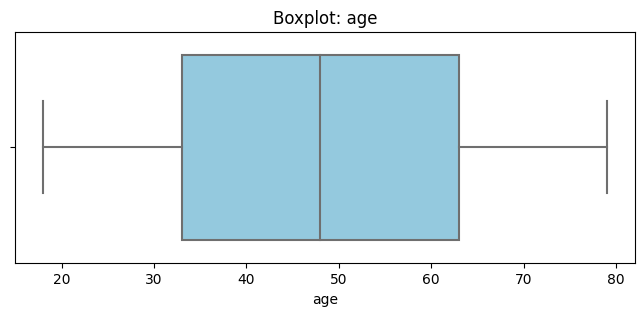

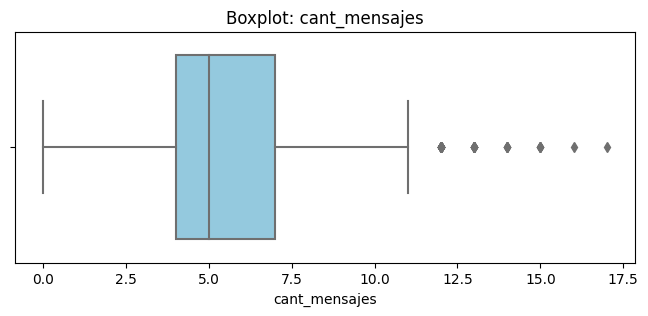

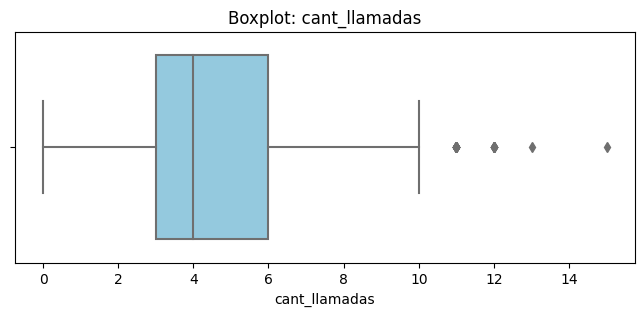

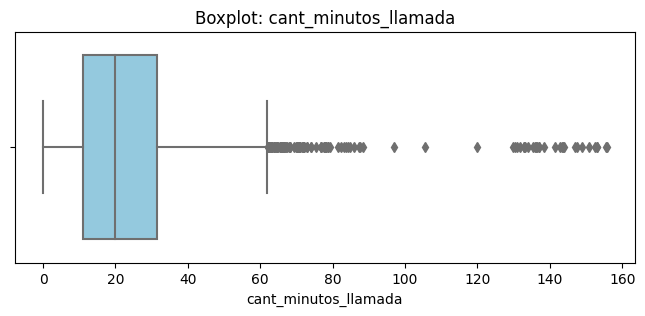

In [40]:
# Visualizando usando BoxPlot 

%matplotlib inline

import seaborn as sns
import matplotlib.pyplot as plt

# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 3))
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- Age: no tiene outliers: el rango de 18 a 79 años queda dentro de los bigotes y la distribución es simétrica.
- cant_mensajes y cant_llamadas: tienen pocos outliers, solo del lado derecho (mensajes de 12 a 17; llamadas de 11 a 15). Son usuarios con uso alto pero plausible.
- cant_minutos_llamada: es la variable con más outliers, también solo a la derecha: una cantidad considerable desde unos 62 minutos y un grupo más aislado entre 130 y 155, muy alejado del resto.
Todos los outliers están en el extremo alto; no hay valores atípicos bajos.

In [41]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    n_outliers = (user_profile[col] > limite_superior).sum()
    pct = n_outliers / len(user_profile) * 100
    print(f"{col}: Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f}, "
          f"límite superior={limite_superior:.2f}, "
          f"outliers={n_outliers} ({pct:.1f}%)")


cant_mensajes: Q1=4.00, Q3=7.00, IQR=3.00, límite superior=11.50, outliers=46 (1.1%)
cant_llamadas: Q1=3.00, Q3=6.00, IQR=3.00, límite superior=10.50, outliers=30 (0.8%)
cant_minutos_llamada: Q1=11.11, Q3=31.41, IQR=20.30, límite superior=61.87, outliers=109 (2.7%)


In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? Mantener los outliers. El límite superior es ≈ 11.5 y el máximo es 17, así que solo unos pocos usuarios (12 a 17 mensajes) lo superan. Son valores plausibles de usuarios intensivos, no errores de captura (no hay negativos ni cifras imposibles).
- cant_llamadas: mantener o no outliers, porqué? mantener los outliers. El límite superior es ≈ 10.5 y el máximo es 15. Los pocos usuarios con 11 a 15 llamadas son clientes muy activos, pero dentro de lo posible. Eliminarlos quitaría información real de uso.
- cant_minutos_llamada: mantener o no outliers, porqué? mantener los outliers. El límite superior es ≈ 61.9 y el máximo es 155.7 (≈ 2.5 veces el límite). Es la variable con más outliers, pero siguen siendo posibles: un usuario con varias llamadas largas (una sola llamada llegaba hasta 120 minutos) acumula minutos altos de forma legítima. Además, los outliers de minutos son coherentes con los de llamadas, lo que refuerza que son uso real y no error.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [42]:
# Crear columna grupo_uso
import numpy as np

# Crear columna grupo_uso
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]
categorias = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(condiciones, categorias, default='Alto uso')

# Verificar resultado
user_profile['grupo_uso'].value_counts()

Uso medio    2943
Bajo uso      779
Alto uso      278
Name: grupo_uso, dtype: int64

In [43]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [44]:
# Crear columna grupo_edad
import numpy as np

# Crear columna grupo_edad
condiciones = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]
categorias = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(condiciones, categorias, default='Adulto Mayor')

# Verificar resultado
user_profile['grupo_edad'].value_counts()

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64

In [45]:

# verificar cambios
user_profile.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

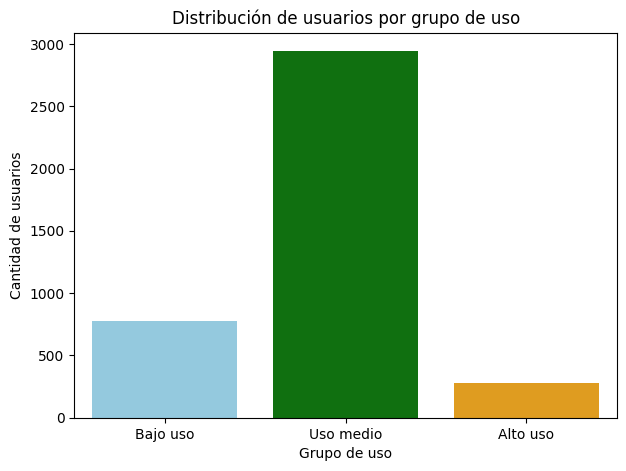

In [46]:
# Visualización de los segmentos por uso
plt.figure(figsize=(7, 5))
sns.countplot(data=user_profile, x='grupo_uso',
              order=['Bajo uso', 'Uso medio', 'Alto uso'],
              palette=['skyblue', 'green', 'orange'])
plt.title('Distribución de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

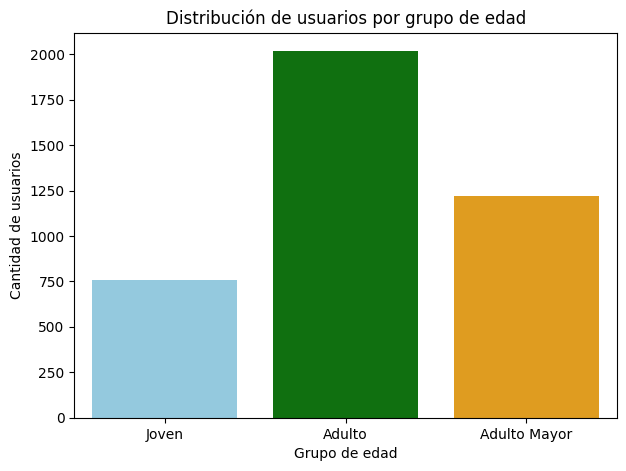

In [47]:
# Visualización de los segmentos por edad
plt.figure(figsize=(7, 5))
sns.countplot(data=user_profile, x='grupo_edad',
              order=['Joven', 'Adulto', 'Adulto Mayor'],
              palette=['skyblue', 'green', 'orange'])
plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

In [49]:
# Conteo y porcentaje de cada segmento
user_profile['grupo_uso'].value_counts(), user_profile['grupo_edad'].value_counts(normalize=True).mul(100).round(1)

# Comportamiento promedio por grupo de edad
user_profile.groupby('grupo_edad')[['cant_mensajes','cant_llamadas','cant_minutos_llamada']].mean().round(1)

# Grupo de uso por grupo de edad (% dentro de cada edad)
pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'], normalize='index').mul(100).round(1)

# Grupo de uso por plan
pd.crosstab(user_profile['plan'], user_profile['grupo_uso'], normalize='index').mul(100).round(1)

grupo_uso,Alto uso,Bajo uso,Uso medio
plan,,,
Basico,7.1,19.8,73.1
Premium,6.6,18.9,74.4



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- age: 55 registros (1.4%)tenía el sentinela -999. Distorsionaba la media y la desviación estándar. Se reemplazó por la mediana.
- city: 565 faltantes (14.1% de 4,000 usuarios): 469 nulos y 96 con el sentinela “?”. Se convirtieron a nulo.
- reg_date: 40 registros (1.0%) con año 2026, imposible porque los datos llegan hasta 2024. Se marcaron como nulos.
- usage.date: 50 nulos (0.1% de 40,000 filas), que se recomienda eliminar.
- churn_date: 3,534 nulos (88.4%). No es un error: significa usuario activo. 466 usuarios (11.6%) ya se dieron de baja.
- duration y length: 55.2% y 44.7% de nulos, estructurales: la duración solo aplica a llamadas y la longitud solo a textos. Se dejaron como nulos.


🔍 **Segmentos por Edad**
- Adulto (30-59): ≈2,020 usuarios (aproximadamente un 50%), es el segmento más grande.
- Adulto Mayor (60+): 1,220 (aproximadamente 30%).
- Joven (<30): ≈760 (19%), el más pequeño.
La edad se distribuye casi uniforme entre 18 y 79 años, así que el tamaño de cada grupo depende sobre todo del ancho de su rango (30 años en Adulto, 12 en Joven).

📊 **Segmentos por Nivel de Uso**
- Uso medio: ≈2,940 usuarios (≈74%), el núcleo de la base.
- Bajo uso: ≈780 (≈19.5%).
- Alto uso: ≈280 (≈7%), pequeño pero muy activo.
Por plan: la distribución es casi idéntica en Basico (19.8% Bajo, 73.1% Medio, 7.1% Alto) y Premium (18.9%, 74.4%, 6.6%). Ambos picos coinciden en 5 mensajes, 4 llamadas y ≈15 minutos.


➡️ Esto sugiere que el plan no distingue el nivel de uso: los clientes Premium no consumen más que los Basico.

Hallazgos: 
Segmentos más valiosos
- Alto uso (≈7%): genera más tráfico y minutos, por lo que tiene el mayor potencial de ingreso y el mayor costo si se va a la competencia.
- Uso medio (≈74%): es el más valioso en volumen, porque sostiene la base de ingresos.
- Adulto (30-59): es el grupo de edad más grande (la mitad de la base). Si es también el que más usa, no se puede afirmar sin el cruce por edad.

Patrones de uso extremo (outliers)
- Hay outliers solo en el extremo alto: mensajes (12 a 17), llamadas (11 a 15) y minutos (≈62 a 155.7). No hay valores negativos ni imposibles.
- Se conservaron, porque son usuarios intensivos reales y justo el segmento que más interesa al negocio.
Implicación: existe un grupo pequeño con consumo muy superior al típico, que probablemente la oferta actual no atiende de forma diferenciada.


**Recomendaciones**

- Revisar la propuesta de valor de Premium: su patrón de uso es igual al de Basico. Puede ofrecer beneficios que esta base no mide (datos, roaming), así que conviene validarlo antes de rediseñarlo.
- Plan para Alto uso (≈7%): minutos o llamadas ampliadas a un precio mayor, para capturar valor y retener a los clientes más activos.
- Plan de entrada para Bajo uso (≈19.5%): tarifa ajustada a su consumo, para reducir el riesgo de baja.
- Retención: analizar edad, plan y uso de los 466 usuarios que ya se dieron de baja, y activar acciones sobre Bajo uso.
- Calidad de datos: corregir en origen la captura de age, city y reg_date, que generaron sentinelas y fechas imposibles.


---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`